# VCU Log Plotter

Choose a decoded log number and the signals to plot in the **User settings** cell, then run all cells. The notebook discovers and loads the matching `MEAS####.csv`, `DERI####.csv`, and `CELL####.csv` files from `DATA_DIR`.

Normal signals use the form `SOURCE.column_name`, for example `MEAS.bus_voltage_v` or `DERI.speed_mph`. Cell voltage and temperature data are configured separately because `CELL####.csv` stores cell data in long format.

## Imports

In [1]:
from pathlib import Path
import math
import re

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

## User settings

Edit this cell to choose a log and any desired signals. Put signals with the same scale on the same axis. Use `right_signals` when a group needs a second y-axis.

In [2]:
# Directory created by vcu_bin_to_csv.py
DATA_DIR = Path("converted")

# Select the numeric suffix of MEAS####/DERI####/CELL####.csv.
LOG_NUMBER = 132

# Set to (start_seconds, end_seconds) to zoom every plot, or None for the full log.
TIME_RANGE_S = (200,1000)

# Limit points per trace so large logs remain responsive.
MAX_POINTS_PER_TRACE = 10_000

# Signals included in the important summary statistics table.
# Each entry may also provide a friendly label and engineering unit.
SUMMARY_SIGNALS = [
    {"signal": "DERI.speed_mph", "label": "Vehicle speed", "unit": "mph"},
    {"signal": "MEAS.motor_rpm", "label": "Motor speed", "unit": "rpm"},
    {"signal": "DERI.commanded_torque_nm", "label": "Commanded torque", "unit": "Nm"},
    {"signal": "DERI.power_kw", "label": "Power", "unit": "kW"},
    {"signal": "MEAS.bus_voltage_v", "label": "HV bus voltage", "unit": "V"},
    {"signal": "MEAS.bus_current_a", "label": "HV bus current", "unit": "A"},
    {"signal": "MEAS.soc_pct", "label": "State of charge", "unit": "%"},
    {"signal": "MEAS.min_cell_voltage_v", "label": "Minimum cell voltage", "unit": "V"},
    {"signal": "MEAS.max_cell_voltage_v", "label": "Maximum cell voltage", "unit": "V"},
    {"signal": "MEAS.avg_cell_temp_c", "label": "Average cell temperature", "unit": "degC"},
    {"signal": "MEAS.inverter_temp_c", "label": "Inverter temperature", "unit": "degC"},
    {"signal": "MEAS.motor_temp_c", "label": "Motor temperature", "unit": "degC"},
]

# Add, remove, or regroup any MEAS/DERI signals listed by the signal table below.
PLOT_GROUPS = [
    {
        "title": "HV bus current and voltage",
        "ylabel": "Current (A)",
        "signals": ["MEAS.bus_current_a"],
        "right_ylabel": "Voltage (V)",
        "right_signals": ["MEAS.bus_voltage_v"],
    },
    {
        "title": "Torque and motor speed",
        "ylabel": "Torque (Nm)",
        "signals": ["DERI.commanded_torque_nm", "DERI.regen_torque_nm"],
        "right_ylabel": "Motor speed (rpm)",
        "right_signals": ["MEAS.motor_rpm"],
    },
    {
        "title": "Temperatures",
        "ylabel": "Temperature (degC)",
        "signals": [
            "MEAS.battery_temp_c",
            "MEAS.inverter_temp_c",
            "MEAS.motor_temp_c",
            "MEAS.avg_cell_temp_c",
        ],
    },
    {
        "title": "IMU acceleration",
        "ylabel": "Acceleration (g)",
        "signals": ["MEAS.accel_x_g", "MEAS.accel_y_g", "MEAS.accel_z_g"],
    },
]

# Optional CELL plots. Use record_type "voltage" or "temperature".
# Set cell_indices to None to plot every cell (usually visually crowded).
CELL_PLOT_GROUPS = [
    {
        "title": "Selected cell voltages",
        "record_type": "voltage",
        "cell_indices": [1, 24, 48, 72, 96],
    },
]

## Loader and plotting helpers

In [3]:
LOG_FILE_RE = re.compile(r"^(?P<source>MEAS|DERI|CELL)(?P<number>\d+)\.csv$", re.IGNORECASE)
META_COLUMNS = {"session", "record_type", "record_type_id", "time_seconds", "elapsed_s"}


def resolve_data_dir(data_dir):
    path = Path(data_dir).expanduser()
    if path.is_absolute():
        return path
    return (Path.cwd() / path).resolve()


def discover_logs(data_dir):
    data_dir = resolve_data_dir(data_dir)
    if not data_dir.is_dir():
        raise FileNotFoundError(f"Data directory not found: {data_dir}")

    logs = {}
    for path in sorted(data_dir.glob("*.csv")):
        match = LOG_FILE_RE.match(path.name)
        if match is None:
            continue
        number = int(match.group("number"))
        source = match.group("source").upper()
        if source in logs.setdefault(number, {}):
            raise ValueError(f"Duplicate {source} file for log {number}: {path}")
        logs[number][source] = path

    if not logs:
        raise FileNotFoundError(f"No MEAS####, DERI####, or CELL#### CSV files found in {data_dir}")
    return dict(sorted(logs.items()))


def available_logs_table(discovered):
    rows = []
    for number, files in discovered.items():
        rows.append({
            "log_number": number,
            "MEAS": files.get("MEAS", Path("")).name,
            "DERI": files.get("DERI", Path("")).name,
            "CELL": files.get("CELL", Path("")).name,
        })
    return pd.DataFrame(rows)


def load_log(data_dir, log_number):
    discovered = discover_logs(data_dir)
    log_number = int(log_number)
    if log_number not in discovered:
        choices = ", ".join(str(number) for number in discovered)
        raise KeyError(f"Log {log_number} was not found. Available log numbers: {choices}")

    files = discovered[log_number]
    frames = {source: pd.read_csv(path, low_memory=False) for source, path in files.items()}

    starts = []
    for frame in frames.values():
        if "time_seconds" in frame:
            times = pd.to_numeric(frame["time_seconds"], errors="coerce").dropna()
            if not times.empty:
                starts.append(times.min())
    time_origin = min(starts) if starts else 0.0

    for source, frame in frames.items():
        if "time_seconds" not in frame:
            raise ValueError(f"{files[source].name} has no time_seconds column")
        elapsed = pd.to_numeric(frame["time_seconds"], errors="coerce") - time_origin
        frame.insert(4, "elapsed_s", elapsed)

    return {
        "number": log_number,
        "id": f"LOG{log_number:04d}",
        "directory": resolve_data_dir(data_dir),
        "files": files,
        "data": frames,
    }


def numeric_values(series):
    values = pd.to_numeric(series, errors="coerce")
    return values.mask(values <= -999)


def available_signals(log):
    rows = []
    for source in ("MEAS", "DERI"):
        frame = log["data"].get(source)
        if frame is None:
            continue
        for column in frame.columns:
            if column in META_COLUMNS:
                continue
            values = numeric_values(frame[column]).dropna()
            if values.empty:
                continue
            populated = frame[column].notna()
            record_types = sorted(frame.loc[populated, "record_type"].astype(str).unique())
            rows.append({
                "signal": f"{source}.{column}",
                "record_type": ", ".join(record_types),
                "samples": len(values),
                "minimum": values.min(),
                "maximum": values.max(),
            })
    return pd.DataFrame(rows)


def summary_statistics(log, signal_specs, time_range_s=None):
    rows = []
    for spec in signal_specs:
        if isinstance(spec, str):
            spec = {"signal": spec}
        signal = spec["signal"]
        data, column = _signal_data(log, signal, time_range_s)
        values = data["value"].dropna()
        rows.append({
            "metric": spec.get("label", _pretty_label(column)),
            "signal": signal,
            "unit": spec.get("unit", ""),
            "samples": int(values.count()),
            "minimum": values.min(),
            "average": values.mean(),
            "maximum": values.max(),
            "median": values.median(),
            "std_dev": values.std(),
            "p05": values.quantile(0.05),
            "p95": values.quantile(0.95),
        })
    return pd.DataFrame(rows)


def run_totals(log, time_range_s=None):
    power, _ = _signal_data(log, "DERI.power_kw", time_range_s)
    power = power.sort_values("elapsed_s").drop_duplicates("elapsed_s", keep="last")

    # Trapezoidal integration: kW * seconds / 3600 = kWh.
    elapsed = power["elapsed_s"]
    consumed_kw = power["value"].clip(lower=0)
    regenerated_kw = (-power["value"]).clip(lower=0)
    delta_s = elapsed.diff()
    valid_intervals = delta_s.gt(0)
    consumed_kwh = (
        0.5 * (consumed_kw + consumed_kw.shift(1)) * delta_s
    ).where(valid_intervals).sum() / 3600.0
    regenerated_kwh = (
        0.5 * (regenerated_kw + regenerated_kw.shift(1)) * delta_s
    ).where(valid_intervals).sum() / 3600.0

    distance, _ = _signal_data(log, "DERI.cumulative_distance_km", time_range_s)
    distance = distance.sort_values("elapsed_s").drop_duplicates("elapsed_s", keep="last")
    distance_km = (
        distance["value"].iloc[-1] - distance["value"].iloc[0]
        if len(distance) >= 2
        else math.nan
    )

    return pd.DataFrame([
        {"metric": "Total energy consumed", "value": consumed_kwh, "unit": "kWh"},
        {"metric": "Total regenerated energy", "value": regenerated_kwh, "unit": "kWh"},
        {"metric": "Cumulative distance", "value": distance_km, "unit": "km"},
    ])


def log_summary(log):
    rows = []
    for source, frame in log["data"].items():
        elapsed = pd.to_numeric(frame["elapsed_s"], errors="coerce").dropna()
        rows.append({
            "source": source,
            "file": log["files"][source].name,
            "rows": len(frame),
            "duration_s": elapsed.max() if not elapsed.empty else math.nan,
        })
    return pd.DataFrame(rows)


def _apply_time_range(frame, time_range_s):
    if time_range_s is None:
        return frame
    start, end = time_range_s
    if start > end:
        raise ValueError("TIME_RANGE_S start must be less than or equal to end")
    return frame.loc[frame["elapsed_s"].between(start, end)]


def _downsample(frame, max_points):
    if not max_points or len(frame) <= max_points:
        return frame
    return frame.iloc[::math.ceil(len(frame) / max_points)]


def _signal_data(log, signal, time_range_s):
    try:
        source, column = signal.split(".", 1)
    except ValueError as exc:
        raise ValueError(f"Signal '{signal}' must use SOURCE.column_name") from exc
    source = source.upper()
    if source not in log["data"]:
        raise KeyError(f"Source {source} is not loaded for {log['id']}")
    frame = log["data"][source]
    if column not in frame:
        raise KeyError(f"Column {column} is not present in {log['files'][source].name}")

    selected = pd.DataFrame({
        "elapsed_s": frame["elapsed_s"],
        "value": numeric_values(frame[column]),
    }).dropna()
    return _apply_time_range(selected, time_range_s), column


def _pretty_label(column):
    return column.replace("_", " ").title()


def _plot_signal_list(ax, log, signals, labels, time_range_s, max_points, color_offset=0):
    lines = []
    colors = plt.get_cmap("tab10").colors
    for index, signal in enumerate(signals):
        data, column = _signal_data(log, signal, time_range_s)
        data = _downsample(data, max_points)
        if data.empty:
            print(f"No values in the selected time range for {signal}")
            continue
        label = labels.get(signal, _pretty_label(column))
        line, = ax.plot(
            data["elapsed_s"],
            data["value"],
            label=label,
            color=colors[(color_offset + index) % len(colors)],
            linewidth=1.15,
        )
        lines.append(line)
    return lines


def _plot_cell_group(ax, log, group, time_range_s, max_points):
    frame = log["data"].get("CELL")
    if frame is None:
        ax.text(0.5, 0.5, "No CELL file loaded", ha="center", va="center", transform=ax.transAxes)
        return []

    record_type = str(group["record_type"]).lower()
    selected = frame.loc[frame["record_type"].astype(str).str.lower().eq(record_type)].copy()
    cell_indices = group.get("cell_indices")
    if cell_indices is not None:
        selected = selected.loc[selected["cell_index"].isin(cell_indices)]
    selected["value"] = numeric_values(selected["value"])
    selected = _apply_time_range(selected.dropna(subset=["elapsed_s", "value"]), time_range_s)

    lines = []
    colors = plt.get_cmap("tab20").colors
    for color_index, (cell_index, cell_frame) in enumerate(selected.groupby("cell_index", sort=True)):
        cell_frame = _downsample(cell_frame, max_points)
        line, = ax.plot(
            cell_frame["elapsed_s"],
            cell_frame["value"],
            label=f"Cell {int(cell_index)}",
            color=colors[color_index % len(colors)],
            linewidth=1.0,
        )
        lines.append(line)

    if not lines:
        ax.text(0.5, 0.5, f"No {record_type} cell data selected", ha="center", va="center", transform=ax.transAxes)
    unit = "V" if record_type == "voltage" else "degC" if record_type == "temperature" else "value"
    ax.set_ylabel(group.get("ylabel", f"Cell {record_type} ({unit})"))
    return lines


def plot_log(log, plot_groups, cell_plot_groups=None, time_range_s=None, max_points=10_000):
    cell_plot_groups = cell_plot_groups or []
    total_plots = len(plot_groups) + len(cell_plot_groups)
    if total_plots == 0:
        raise ValueError("Configure at least one PLOT_GROUPS or CELL_PLOT_GROUPS entry")

    fig, axes_grid = plt.subplots(
        total_plots, 1, figsize=(14, 3.6 * total_plots), squeeze=False, constrained_layout=True
    )
    axes = axes_grid[:, 0]
    fig.suptitle(f"{log['id']} VCU data", fontsize=15)

    for ax, group in zip(axes, plot_groups):
        signals = group.get("signals", [])
        right_signals = group.get("right_signals", [])
        labels = group.get("labels", {})
        lines = _plot_signal_list(
            ax, log, signals, labels, time_range_s, max_points, color_offset=0
        )
        ax.set_title(group.get("title", "Signals"))
        ax.set_ylabel(group.get("ylabel", "Value"))
        ax.grid(True, alpha=0.25)

        right_ax = None
        if right_signals:
            right_ax = ax.twinx()
            lines += _plot_signal_list(
                right_ax, log, right_signals, labels, time_range_s, max_points, color_offset=len(signals)
            )
            right_ax.set_ylabel(group.get("right_ylabel", "Value"))
        if lines:
            ax.legend(lines, [line.get_label() for line in lines], loc="best")
        else:
            ax.text(0.5, 0.5, "No data selected", ha="center", va="center", transform=ax.transAxes)

    cell_start = len(plot_groups)
    for ax, group in zip(axes[cell_start:], cell_plot_groups):
        lines = _plot_cell_group(ax, log, group, time_range_s, max_points)
        ax.set_title(group.get("title", "Cell data"))
        ax.grid(True, alpha=0.25)
        if lines:
            ax.legend(loc="best", ncol=min(4, len(lines)))

    axes[-1].set_xlabel("Elapsed time (s)")
    plt.show()
    return fig, axes

## Load the selected log and inspect available data

The first table shows every discovered log. The next tables summarize the selected files and list every numeric `MEAS`/`DERI` signal that contains data in this log. Copy signal names directly into `PLOT_GROUPS`.

In [4]:
discovered_logs = discover_logs(DATA_DIR)
print(f"Available logs in {resolve_data_dir(DATA_DIR)}")
display(available_logs_table(discovered_logs))

log = load_log(DATA_DIR, LOG_NUMBER)
print(f"Loaded {log['id']}")
display(log_summary(log).round({"duration_s": 3}))

signal_table = available_signals(log)
display(signal_table.round({"minimum": 4, "maximum": 4}))

Available logs in C:\Users\Nathan\Documents\Formula_E\BERT2026\BERT26-Firmware\20260912\VCU_BERT26_V2\converted


,log_number,MEAS,DERI,CELL
0,126,MEAS0126.csv,DERI0126.csv,CELL0126.csv
1,127,MEAS0127.csv,DERI0127.csv,CELL0127.csv
2,128,MEAS0128.csv,DERI0128.csv,CELL0128.csv
3,129,MEAS0129.csv,DERI0129.csv,CELL0129.csv
4,130,MEAS0130.csv,DERI0130.csv,CELL0130.csv
5,131,MEAS0131.csv,DERI0131.csv,CELL0131.csv
6,132,MEAS0132.csv,DERI0132.csv,CELL0132.csv
7,134,MEAS0134.csv,DERI0134.csv,CELL0134.csv
8,135,MEAS0135.csv,DERI0135.csv,CELL0135.csv
9,136,MEAS0136.csv,DERI0136.csv,CELL0136.csv


Loaded LOG0132


,source,file,rows,duration_s
0,CELL,CELL0132.csv,40541,1238.779
1,DERI,DERI0132.csv,118874,1244.500
2,MEAS,MEAS0132.csv,226788,1244.502


,signal,record_type,samples,minimum,maximum
0,MEAS.apps1_adc_counts,fast,106671,231.0000,2381.0000
1,MEAS.apps2_adc_counts,fast,106671,2125.0000,4012.0000
2,MEAS.bse1_adc_counts,fast,106671,436.0000,1647.0000
3,MEAS.bse2_adc_counts,fast,106671,433.0000,2708.0000
4,MEAS.hv_current_adc_counts,fast,106671,1871.0000,3761.0000
5,MEAS.motor_rpm,fast,106671,-286.0000,3240.0000
6,MEAS.bus_voltage_v,fast,106671,0.0000,365.5000
7,MEAS.bus_current_a,fast,106671,-1.2000,162.0000
8,MEAS.glv_voltage_v,medium,12202,11.4700,12.7500
9,MEAS.inverter_temp_c,medium,12202,42.1000,66.3000


## Important summary statistics

The totals table integrates positive `DERI.power_kw` as consumed energy and negative power as regenerated energy. Cumulative distance is the change in `DERI.cumulative_distance_km`. Both tables follow the optional `TIME_RANGE_S`. The statistics table uses `SUMMARY_SIGNALS` and reports the minimum, average, maximum, median, standard deviation, and 5th/95th percentiles.

In [5]:
totals = run_totals(log, time_range_s=TIME_RANGE_S)
display(totals.round({"value": 4}))

important_summary = summary_statistics(
    log,
    SUMMARY_SIGNALS,
    time_range_s=TIME_RANGE_S,
)
display(
    important_summary.round({
        "minimum": 3,
        "average": 3,
        "maximum": 3,
        "median": 3,
        "std_dev": 3,
        "p05": 3,
        "p95": 3,
    })
)

,metric,value,unit
0,Total energy consumed,1.8625,kWh
1,Total regenerated energy,0.0003,kWh
2,Cumulative distance,7.8023,km


,metric,signal,unit,samples,minimum,average,maximum,median,std_dev,p05,p95
0,Vehicle speed,DERI.speed_mph,mph,7786,0.000,21.748,45.208,24.201,12.757,0.000,42.068
1,Motor speed,MEAS.motor_rpm,rpm,64372,-228.000,1502.243,3240.000,1692.000,929.399,0.000,3000.000
2,Commanded torque,DERI.commanded_torque_nm,Nm,64372,-50.000,45.004,169.500,21.800,53.624,0.000,169.200
3,Power,DERI.power_kw,kW,7786,-0.394,8.334,50.463,3.861,10.384,0.000,31.736
4,HV bus voltage,MEAS.bus_voltage_v,V,64372,0.900,320.763,365.500,336.300,73.054,167.060,360.200
5,HV bus current,MEAS.bus_current_a,A,64372,-1.200,24.179,162.000,10.000,32.087,0.000,97.500
6,State of charge,MEAS.soc_pct,%,7786,67.000,76.772,89.000,77.000,6.506,67.000,88.000
7,Minimum cell voltage,MEAS.min_cell_voltage_v,V,798,3.041,3.503,3.792,3.506,0.144,3.278,3.740
8,Maximum cell voltage,MEAS.max_cell_voltage_v,V,798,3.084,3.530,3.810,3.529,0.140,3.314,3.760
9,Average cell temperature,MEAS.avg_cell_temp_c,degC,798,38.000,42.506,47.000,42.000,2.997,38.000,47.000


## Plot the selected data

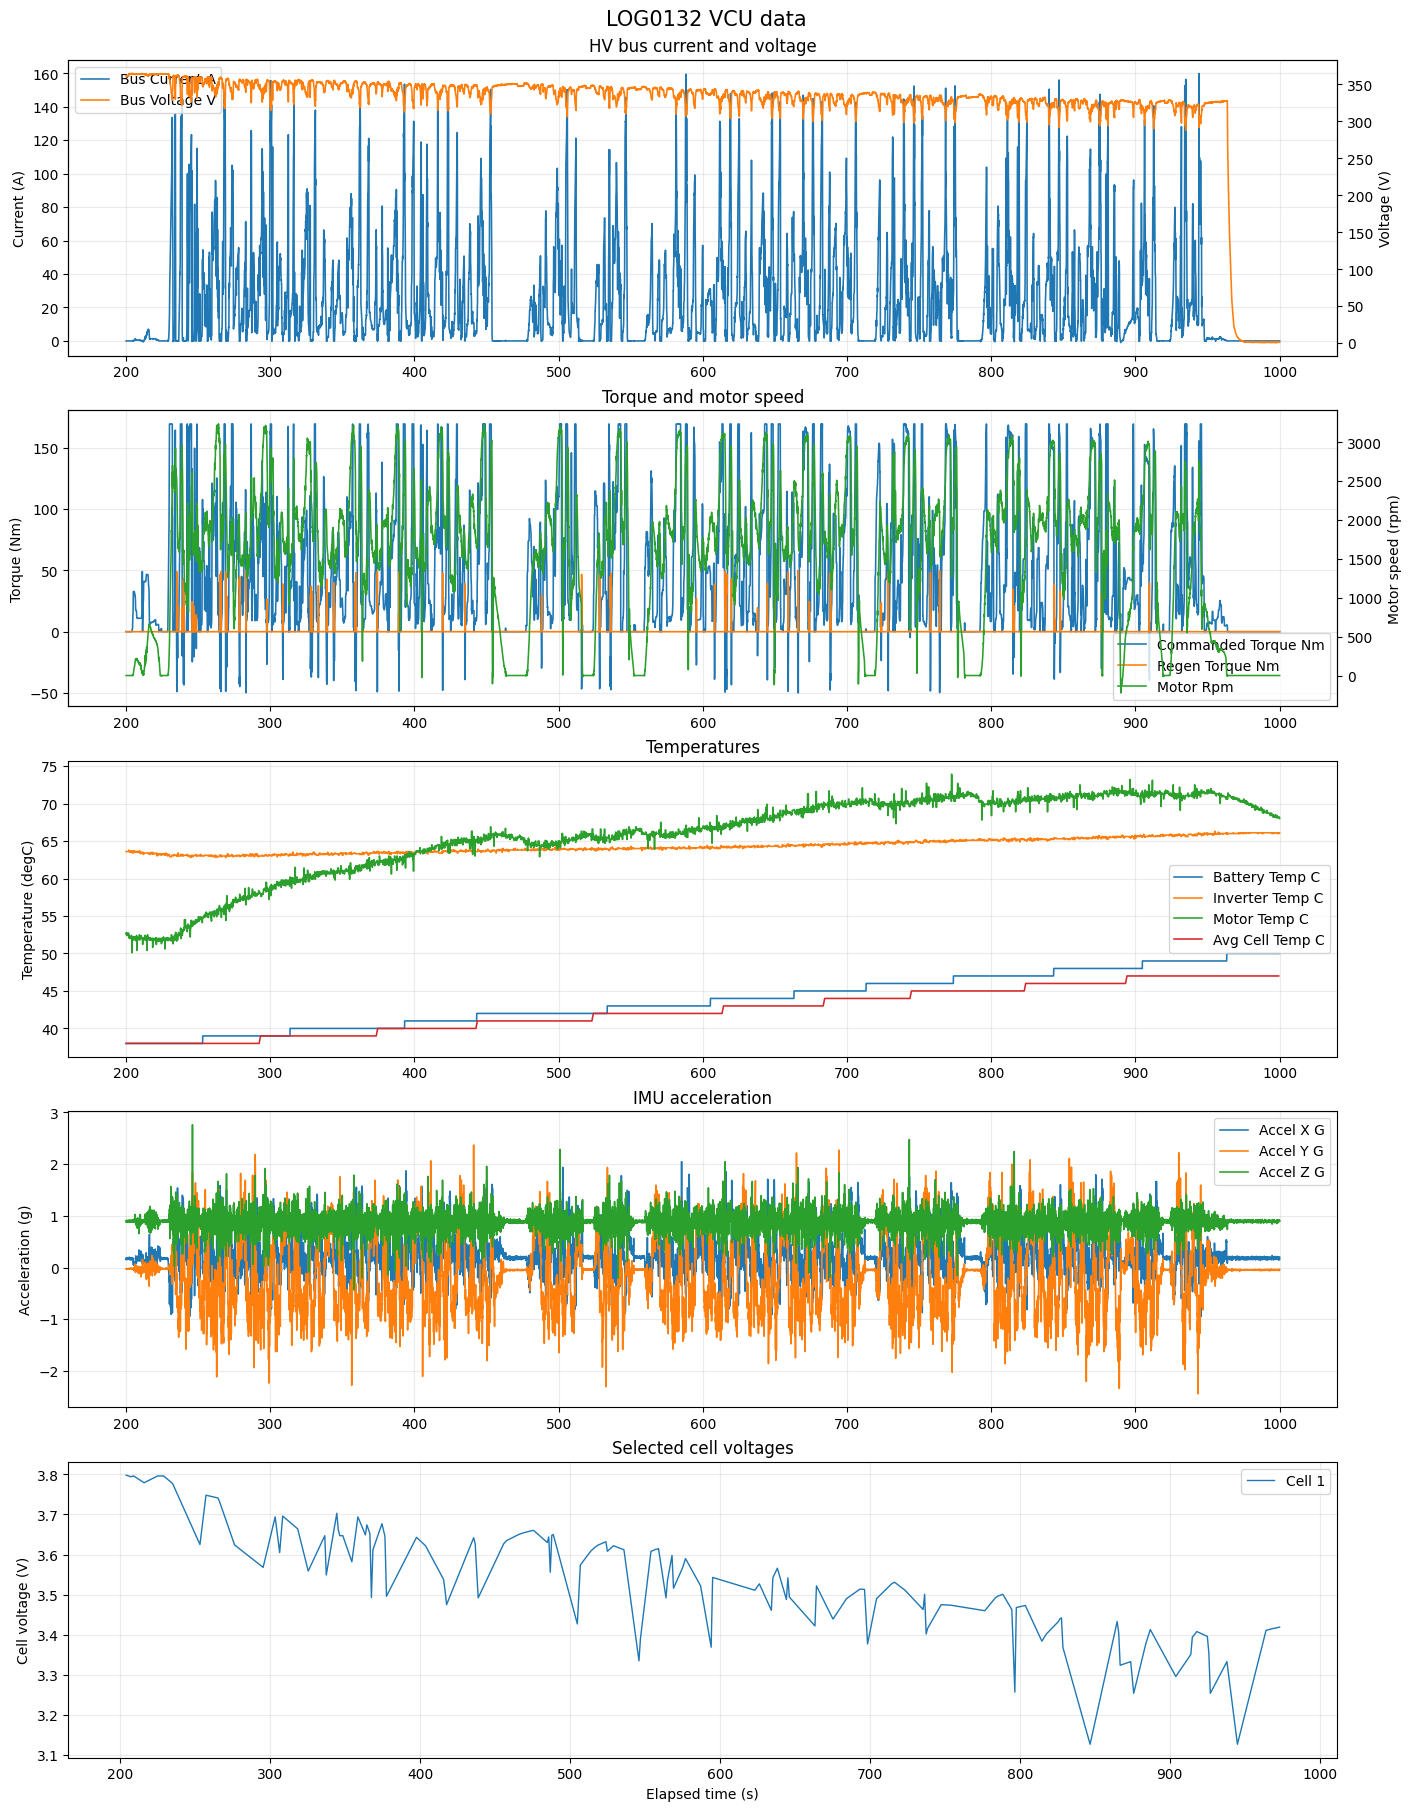

In [6]:
fig, axes = plot_log(
    log,
    PLOT_GROUPS,
    cell_plot_groups=CELL_PLOT_GROUPS,
    time_range_s=TIME_RANGE_S,
    max_points=MAX_POINTS_PER_TRACE,
)

## Configuration examples

`SUMMARY_SIGNALS` accepts either a signal string or a dictionary with optional `label` and `unit` fields. A plot group can contain one or many signals:

```python
{
    "title": "Pedals and brake",
    "ylabel": "Percent",
    "signals": ["DERI.apps1_pct", "DERI.apps2_pct", "DERI.brake_pressure_pct"],
    "labels": {"DERI.apps1_pct": "Accelerator sensor 1"},
}
```

To plot temperature for specific cells, add this to `CELL_PLOT_GROUPS`:

```python
{"title": "Cell temperatures", "record_type": "temperature", "cell_indices": [1, 2, 3]}
```